# Análise Exploratória do WikiArt

Este notebook documenta a etapa de **análise exploratória e curadoria inicial** do dataset `huggan/wikiart` utilizada no TCC.

## Objetivos

1. Inspecionar a estrutura e os metadados do WikiArt.
2. Quantificar a distribuição dos estilos artísticos.
3. Investigar a distribuição de artistas e as limitações relacionadas a `Unknown Artist`.
4. Analisar a distribuição dos gêneros temáticos.
5. Consolidar as quatro macroclasses definidas no escopo do projeto:
   - Renaissance
   - Baroque
   - Impressionism
   - Cubism
6. Identificar associações entre gênero temático e macroclasse que possam favorecer *shortcut learning*.

> Este notebook é destinado à **EDA**. A seleção definitiva das pinturas, auditoria de integridade, balanceamento e divisão em treino/validação/teste serão realizados no notebook de curadoria.

## 1. Configuração do ambiente

As dependências do projeto devem ser instaladas a partir do `requirements.txt` localizado na raiz do repositório.

O notebook também localiza automaticamente a raiz do projeto para permitir a importação dos módulos presentes em `src/`, independentemente de ele ser executado a partir da raiz ou da pasta `notebooks/`.

In [22]:
from itertools import combinations
from pathlib import Path
import sys

from datasets import load_dataset
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd


def encontrar_raiz_projeto(inicio: Path = Path.cwd()) -> Path:
    """Localiza a raiz do repositório procurando pela pasta src/."""
    for caminho in [inicio, *inicio.parents]:
        if (caminho / "src").is_dir():
            return caminho

    raise FileNotFoundError(
        "Não foi possível localizar a raiz do projeto. "
        "Verifique se a pasta 'src/' existe no repositório."
    )


RAIZ_PROJETO = encontrar_raiz_projeto()

if str(RAIZ_PROJETO) not in sys.path:
    sys.path.insert(0, str(RAIZ_PROJETO))

print(f"Raiz do projeto: {RAIZ_PROJETO}")

Raiz do projeto: c:\Users\Brum_\OneDrive\Documentos 1\TCC\Wikiart


## 2. Carregamento do dataset

O projeto utiliza exclusivamente o dataset público `huggan/wikiart`, disponibilizado no Hugging Face.

O conjunto possui uma única partição original (`train`). As divisões de treino, validação e teste do experimento serão criadas posteriormente, **no nível da pintura completa e antes da geração dos patches**.

In [23]:
dataset = load_dataset("huggan/wikiart")
train = dataset["train"]

print(dataset)
print(f"Total de obras: {len(train):,}".replace(",", "."))

Resolving data files:   0%|          | 0/72 [00:00<?, ?it/s]

Loading dataset shards:   0%|          | 0/45 [00:00<?, ?it/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'artist', 'genre', 'style'],
        num_rows: 81444
    })
})
Total de obras: 81.444


In [24]:
print("Features disponíveis:")
display(train.features)

Features disponíveis:


{'image': Image(mode=None, decode=True),
 'artist': ClassLabel(names=['Unknown Artist', 'boris-kustodiev', 'camille-pissarro', 'childe-hassam', 'claude-monet', 'edgar-degas', 'eugene-boudin', 'gustave-dore', 'ilya-repin', 'ivan-aivazovsky', 'ivan-shishkin', 'john-singer-sargent', 'marc-chagall', 'martiros-saryan', 'nicholas-roerich', 'pablo-picasso', 'paul-cezanne', 'pierre-auguste-renoir', 'pyotr-konchalovsky', 'raphael-kirchner', 'rembrandt', 'salvador-dali', 'vincent-van-gogh', 'hieronymus-bosch', 'leonardo-da-vinci', 'albrecht-durer', 'edouard-cortes', 'sam-francis', 'juan-gris', 'lucas-cranach-the-elder', 'paul-gauguin', 'konstantin-makovsky', 'egon-schiele', 'thomas-eakins', 'gustave-moreau', 'francisco-goya', 'edvard-munch', 'henri-matisse', 'fra-angelico', 'maxime-maufra', 'jan-matejko', 'mstislav-dobuzhinsky', 'alfred-sisley', 'mary-cassatt', 'gustave-loiseau', 'fernando-botero', 'zinaida-serebriakova', 'georges-seurat', 'isaac-levitan', 'joaquã\xadn-sorolla', 'jacek-malczewsk

## 3. Construção da tabela de metadados

Para a EDA, os identificadores numéricos de `style`, `artist` e `genre` são convertidos para os nomes definidos pelo próprio dataset.

A coluna `Indice_Dataset` preserva a posição original da obra dentro da partição carregada e será útil para rastreabilidade durante as próximas etapas.

In [25]:
style_names = train.features["style"].names
artist_names = train.features["artist"].names
genre_names = train.features["genre"].names

df_meta = pd.DataFrame({
    "Indice_Dataset": range(len(train)),
    "style_id": train["style"],
    "artist_id": train["artist"],
    "genre_id": train["genre"],
})

df_meta["Estilo"] = df_meta["style_id"].map(lambda x: style_names[x])
df_meta["Artista"] = df_meta["artist_id"].map(lambda x: artist_names[x])
df_meta["Genero"] = df_meta["genre_id"].map(lambda x: genre_names[x])

display(df_meta.head())

print(f"Estilos: {df_meta['Estilo'].nunique()}")
print(f"Artistas rotulados: {df_meta['Artista'].nunique()}")
print(f"Gêneros: {df_meta['Genero'].nunique()}")

,Indice_Dataset,style_id,artist_id,genre_id,Estilo,Artista,Genero
0,0,21,22,4,Realism,vincent-van-gogh,landscape
1,1,4,20,7,Baroque,rembrandt,religious_painting
2,2,20,16,6,Post_Impressionism,paul-cezanne,portrait
3,3,12,17,2,Impressionism,pierre-auguste-renoir,genre_painting
4,4,23,9,10,Romanticism,ivan-aivazovsky,Unknown Genre


Estilos: 27
Artistas rotulados: 129
Gêneros: 11


## 4. Distribuição das obras por estilo

A primeira análise verifica quantas obras estão disponíveis em cada um dos 27 rótulos de estilo do WikiArt. Essa distribuição permite avaliar a viabilidade das classes e evidencia o desbalanceamento natural do dataset.

In [26]:
df_estilos = (
    df_meta["Estilo"]
    .value_counts()
    .rename_axis("Estilo")
    .reset_index(name="Quantidade")
)

display(df_estilos)

,Estilo,Quantidade
0,Impressionism,13060
1,Realism,10733
2,Romanticism,7019
3,Expressionism,6736
4,Post_Impressionism,6450
5,Symbolism,4528
6,Art_Nouveau,4334
7,Baroque,4240
8,Abstract_Expressionism,2782
9,Northern_Renaissance,2552


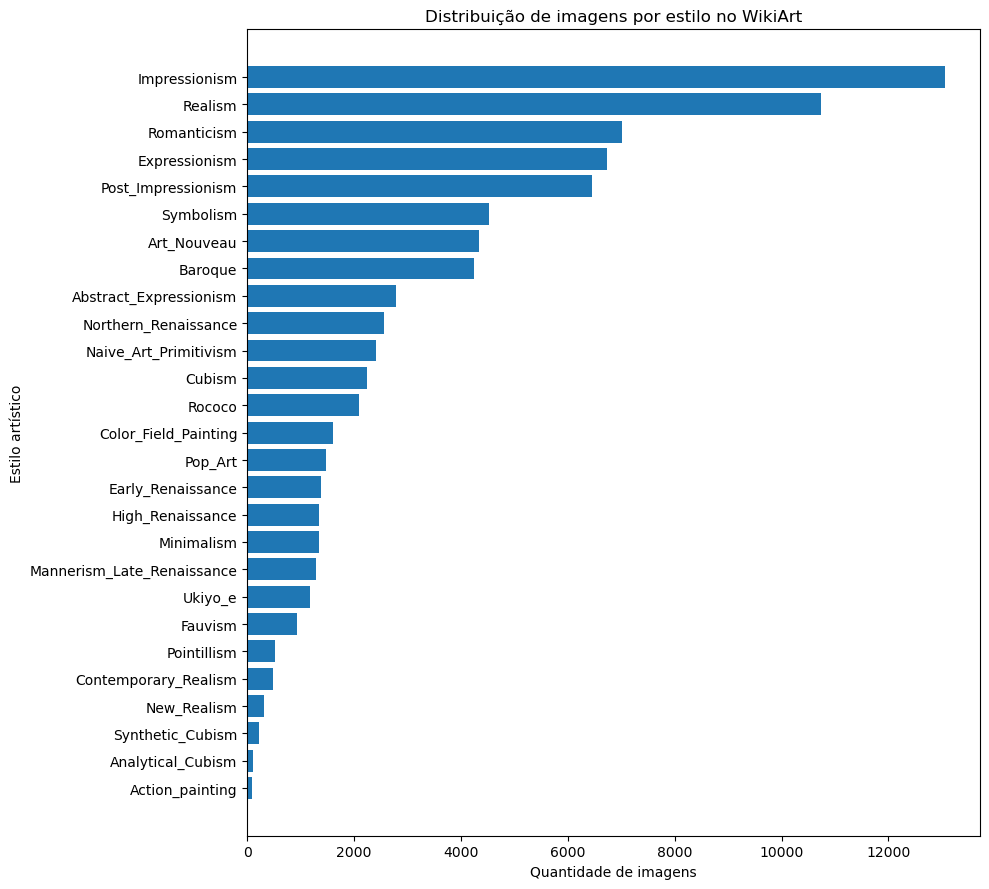

In [27]:
plt.figure(figsize=(10, 9))

plt.barh(
    df_estilos["Estilo"],
    df_estilos["Quantidade"],
)

plt.xlabel("Quantidade de imagens")
plt.ylabel("Estilo artístico")
plt.title("Distribuição de imagens por estilo no WikiArt")
plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

## 5. Análise de autoria

A autoria foi analisada para investigar se alguma classe estava excessivamente concentrada em poucos artistas.

Entretanto, o WikiArt possui grande quantidade de registros com `Unknown Artist`. Esse rótulo pode representar várias autorias não identificadas e, portanto, **não deve ser interpretado como um único artista dominante**.

Por esse motivo, a autoria é documentada como característica e limitação dos metadados, mas não será utilizada como principal critério de balanceamento das classes.

In [28]:
resumo_artistas = (
    df_meta.groupby("Estilo")
    .agg(
        Quantidade_Obras=("Artista", "size"),
        Artistas_Distintos=("Artista", "nunique"),
    )
    .reset_index()
    .sort_values("Quantidade_Obras", ascending=False)
)

display(resumo_artistas)

,Estilo,Quantidade_Obras,Artistas_Distintos
12,Impressionism,13060,53
21,Realism,10733,58
23,Romanticism,7019,24
9,Expressionism,6736,16
20,Post_Impressionism,6450,29
24,Symbolism,4528,26
3,Art_Nouveau,4334,23
4,Baroque,4240,10
0,Abstract_Expressionism,2782,6
17,Northern_Renaissance,2552,6


In [29]:
artistas_por_estilo = (
    df_meta.groupby(["Estilo", "Artista"])
    .size()
    .reset_index(name="Quantidade")
)

artistas_por_estilo["Percentual"] = (
    artistas_por_estilo.groupby("Estilo")["Quantidade"]
    .transform(lambda valores: 100 * valores / valores.sum())
    .round(2)
)

artistas_por_estilo = artistas_por_estilo.sort_values(
    ["Estilo", "Quantidade"],
    ascending=[True, False],
)

artista_mais_frequente = (
    artistas_por_estilo
    .groupby("Estilo", as_index=False)
    .first()
)

display(
    artista_mais_frequente[
        ["Estilo", "Artista", "Quantidade", "Percentual"]
    ]
)

,Estilo,Artista,Quantidade,Percentual
0,Abstract_Expressionism,Unknown Artist,2471,88.82
1,Action_painting,Unknown Artist,98,100.00
2,Analytical_Cubism,pablo-picasso,50,45.45
3,Art_Nouveau,Unknown Artist,2095,48.34
4,Baroque,Unknown Artist,2544,60.00
5,Color_Field_Painting,Unknown Artist,1405,87.00
6,Contemporary_Realism,Unknown Artist,471,97.92
7,Cubism,Unknown Artist,1457,65.19
8,Early_Renaissance,Unknown Artist,1132,81.38
9,Expressionism,Unknown Artist,4290,63.69


In [30]:
unknown_artist_por_estilo = (
    artistas_por_estilo[
        artistas_por_estilo["Artista"] == "Unknown Artist"
    ][["Estilo", "Quantidade", "Percentual"]]
    .sort_values("Percentual", ascending=False)
    .reset_index(drop=True)
)

display(unknown_artist_por_estilo)

,Estilo,Quantidade,Percentual
0,Action_painting,98,100.00
1,New_Realism,314,100.00
2,Minimalism,1332,99.63
3,Contemporary_Realism,471,97.92
4,Pop_Art,1379,92.99
5,Abstract_Expressionism,2471,88.82
6,Color_Field_Painting,1405,87.00
7,Fauvism,771,82.55
8,Rococo,1703,81.52
9,Early_Renaissance,1132,81.38


### Conclusão sobre autoria

A presença expressiva de `Unknown Artist` reduz a confiabilidade de análises de concentração por autor. Assim, a seleção das macroclasses não será baseada no artista mais frequente. A limitação será registrada na documentação do TCC.

## 6. Distribuição de gêneros nos 27 estilos

O campo `genre` representa o tema ou tipo de pintura (`portrait`, `landscape`, `religious_painting`, entre outros).

Essa variável é especialmente relevante porque pode funcionar como um **atalho temático**: uma rede pode associar determinado conteúdo visual a um movimento artístico sem necessariamente utilizar características estilísticas.

In [31]:
generos_por_estilo = (
    df_meta.groupby(["Estilo", "Genero"])
    .size()
    .reset_index(name="Quantidade")
)

generos_por_estilo["Percentual"] = (
    generos_por_estilo.groupby("Estilo")["Quantidade"]
    .transform(lambda valores: 100 * valores / valores.sum())
    .round(2)
)

generos_por_estilo = generos_por_estilo.sort_values(
    ["Estilo", "Quantidade"],
    ascending=[True, False],
)

tabela_generos = (
    pd.crosstab(
        df_meta["Estilo"],
        df_meta["Genero"],
        normalize="index",
    )
    * 100
).round(2)

display(generos_por_estilo.head(20))
display(tabela_generos)

,Estilo,Genero,Quantidade,Percentual
1,Abstract_Expressionism,abstract_painting,2208,79.37
0,Abstract_Expressionism,Unknown Genre,488,17.54
7,Abstract_Expressionism,portrait,20,0.72
4,Abstract_Expressionism,illustration,16,0.58
6,Abstract_Expressionism,nude_painting,13,0.47
5,Abstract_Expressionism,landscape,12,0.43
3,Abstract_Expressionism,genre_painting,7,0.25
9,Abstract_Expressionism,sketch_and_study,7,0.25
8,Abstract_Expressionism,religious_painting,4,0.14
10,Abstract_Expressionism,still_life,4,0.14


Genero,Unknown Genre,abstract_painting,cityscape,genre_painting,illustration,landscape,nude_painting,portrait,religious_painting,sketch_and_study,still_life
Estilo,,,,,,,,,,,
Abstract_Expressionism,17.54,79.37,0.11,0.25,0.58,0.43,0.47,0.72,0.14,0.25,0.14
Action_painting,2.04,94.90,0.00,0.00,0.00,0.00,3.06,0.00,0.00,0.00,0.00
Analytical_Cubism,0.00,0.00,2.73,28.18,0.00,4.55,4.55,14.55,0.00,0.00,45.45
Art_Nouveau,40.45,0.00,4.59,13.96,14.84,6.18,1.57,12.21,2.40,3.55,0.25
Baroque,20.21,0.02,1.27,18.14,0.14,4.22,0.80,23.11,24.43,4.76,2.88
Color_Field_Painting,6.07,93.75,0.00,0.00,0.19,0.00,0.00,0.00,0.00,0.00,0.00
Contemporary_Realism,19.33,0.21,1.66,11.02,0.00,35.97,11.23,14.76,0.00,0.21,5.61
Cubism,22.01,5.73,6.44,12.93,0.22,9.08,5.68,14.45,0.89,3.76,18.79
Early_Renaissance,5.54,0.00,0.07,0.86,0.86,0.22,0.00,7.33,78.94,6.18,0.00


## 7. Definição das quatro macroclasses

O escopo do TCC estabelece quatro classes finais. Para preservar a rastreabilidade, o rótulo original `Estilo` continua disponível e uma nova coluna, `Macro_Estilo`, é criada.

### Renaissance
- `Early_Renaissance`
- `High_Renaissance`
- `Northern_Renaissance`
- `Mannerism_Late_Renaissance`

### Cubism
- `Cubism`
- `Analytical_Cubism`
- `Synthetic_Cubism`

### Classes mantidas sem agregação
- `Baroque`
- `Impressionism`

O mapeamento oficial fica centralizado em `src/data/labels.py`, evitando definições divergentes entre notebooks e scripts.

In [32]:
from src.data.labels import (
    CLASSES_FINAIS,
    ESTILOS_ORIGINAIS_EXPERIMENTO,
    MAPA_MACROCLASSES,
)

df_experimento = df_meta[
    df_meta["Estilo"].isin(ESTILOS_ORIGINAIS_EXPERIMENTO)
].copy()

df_experimento["Macro_Estilo"] = (
    df_experimento["Estilo"]
    .map(MAPA_MACROCLASSES)
)

assert df_experimento["Macro_Estilo"].isna().sum() == 0
assert set(df_experimento["Macro_Estilo"].unique()) == set(CLASSES_FINAIS)

ordem_classes = list(CLASSES_FINAIS)

print("Macroclasses carregadas corretamente.")
display(
    df_experimento["Macro_Estilo"]
    .value_counts()
    .reindex(ordem_classes)
    .rename("Quantidade")
    .to_frame()
)

Macroclasses carregadas corretamente.


,Quantidade
Macro_Estilo,
Renaissance,6565
Baroque,4240
Impressionism,13060
Cubism,2561


In [33]:
composicao_macroclasses = (
    df_experimento
    .groupby(["Macro_Estilo", "Estilo"])
    .size()
    .reset_index(name="Quantidade")
    .sort_values(
        ["Macro_Estilo", "Quantidade"],
        ascending=[True, False],
    )
)

display(composicao_macroclasses)

,Macro_Estilo,Estilo,Quantidade
0,Baroque,Baroque,4240
2,Cubism,Cubism,2235
3,Cubism,Synthetic_Cubism,216
1,Cubism,Analytical_Cubism,110
4,Impressionism,Impressionism,13060
8,Renaissance,Northern_Renaissance,2552
5,Renaissance,Early_Renaissance,1391
6,Renaissance,High_Renaissance,1343
7,Renaissance,Mannerism_Late_Renaissance,1279


## 8. Gênero temático por macroclasse

A distribuição é apresentada de duas maneiras:

1. **Distribuição completa**, incluindo `Unknown Genre`.
2. **Distribuição entre gêneros conhecidos**, excluindo `Unknown Genre` antes do cálculo dos percentuais.

Essa separação é importante: por exemplo, dizer que uma porcentagem das obras de uma classe é religiosa considerando todo o conjunto não é equivalente a dizer qual é a participação religiosa apenas entre os registros com gênero conhecido.

In [34]:
generos_macro = (
    df_experimento
    .groupby(["Macro_Estilo", "Genero"])
    .size()
    .reset_index(name="Quantidade")
)

generos_macro["Percentual_Total"] = (
    generos_macro.groupby("Macro_Estilo")["Quantidade"]
    .transform(lambda valores: 100 * valores / valores.sum())
    .round(2)
)

generos_macro = generos_macro.sort_values(
    ["Macro_Estilo", "Quantidade"],
    ascending=[True, False],
)

tabela_generos_macro = (
    pd.crosstab(
        df_experimento["Macro_Estilo"],
        df_experimento["Genero"],
        normalize="index",
    )
    * 100
).reindex(ordem_classes).round(2)

display(tabela_generos_macro)

Genero,Unknown Genre,abstract_painting,cityscape,genre_painting,illustration,landscape,nude_painting,portrait,religious_painting,sketch_and_study,still_life
Macro_Estilo,,,,,,,,,,,
Renaissance,14.49,0.00,0.46,2.32,0.37,0.88,0.62,16.53,56.34,7.86,0.14
Baroque,20.21,0.02,1.27,18.14,0.14,4.22,0.80,23.11,24.43,4.76,2.88
Impressionism,11.70,0.00,11.83,20.44,0.01,33.42,2.76,14.54,0.14,1.87,3.30
Cubism,19.25,5.08,5.78,12.89,0.20,8.28,5.15,13.78,0.78,3.36,25.46


In [35]:
unknown_genero = (
    generos_macro[
        generos_macro["Genero"] == "Unknown Genre"
    ][["Macro_Estilo", "Quantidade", "Percentual_Total"]]
    .set_index("Macro_Estilo")
    .reindex(ordem_classes)
)

display(unknown_genero)

,Quantidade,Percentual_Total
Macro_Estilo,,
Renaissance,951,14.49
Baroque,857,20.21
Impressionism,1528,11.70
Cubism,493,19.25


In [36]:
df_generos_conhecidos = df_experimento[
    df_experimento["Genero"] != "Unknown Genre"
].copy()

tabela_generos_sem_unknown = (
    pd.crosstab(
        df_generos_conhecidos["Macro_Estilo"],
        df_generos_conhecidos["Genero"],
        normalize="index",
    )
    * 100
).reindex(ordem_classes).round(2)

print("Distribuição percentual considerando apenas gêneros conhecidos:")
display(tabela_generos_sem_unknown)

Distribuição percentual considerando apenas gêneros conhecidos:


Genero,abstract_painting,cityscape,genre_painting,illustration,landscape,nude_painting,portrait,religious_painting,sketch_and_study,still_life
Macro_Estilo,,,,,,,,,,
Renaissance,0.00,0.53,2.71,0.43,1.03,0.73,19.33,65.89,9.19,0.16
Baroque,0.03,1.60,22.73,0.18,5.29,1.01,28.97,30.62,5.97,3.61
Impressionism,0.00,13.40,23.14,0.01,37.85,3.12,16.47,0.16,2.12,3.74
Cubism,6.29,7.16,15.96,0.24,10.25,6.38,17.07,0.97,4.16,31.53


## 9. Visualização da composição temática

O heatmap e o gráfico de barras empilhadas facilitam a comparação entre as macroclasses e evidenciam gêneros com forte associação a movimentos específicos.

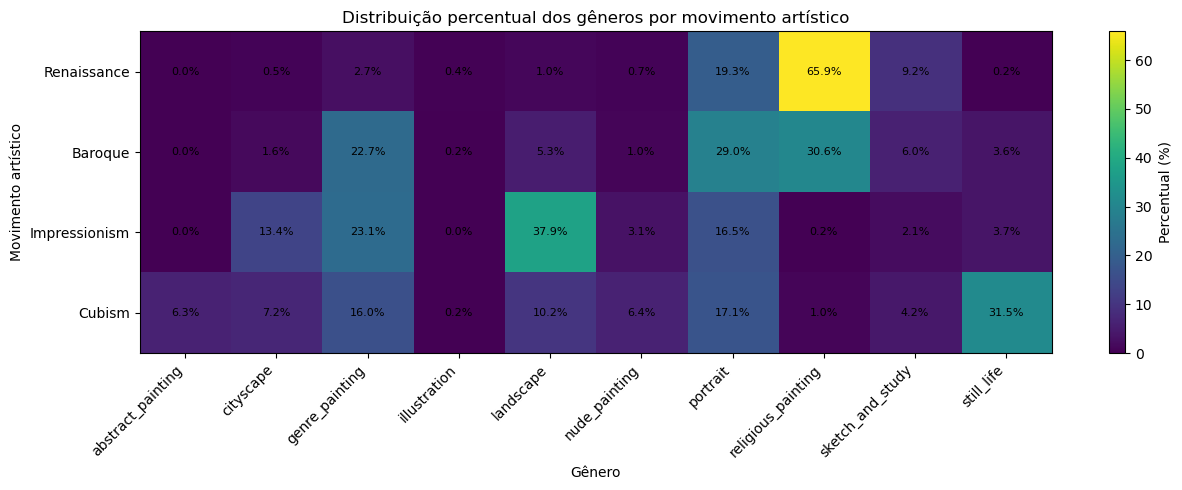

In [37]:
dados_heatmap = tabela_generos_sem_unknown.copy()

fig, ax = plt.subplots(figsize=(13, 5))

imagem = ax.imshow(
    dados_heatmap.values,
    aspect="auto",
)

ax.set_xticks(range(len(dados_heatmap.columns)))
ax.set_xticklabels(
    dados_heatmap.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(range(len(dados_heatmap.index)))
ax.set_yticklabels(dados_heatmap.index)

ax.set_xlabel("Gênero")
ax.set_ylabel("Movimento artístico")
ax.set_title(
    "Distribuição percentual dos gêneros por movimento artístico"
)

for i in range(dados_heatmap.shape[0]):
    for j in range(dados_heatmap.shape[1]):
        valor = dados_heatmap.iloc[i, j]
        ax.text(
            j,
            i,
            f"{valor:.1f}%",
            ha="center",
            va="center",
            fontsize=8,
        )

fig.colorbar(
    imagem,
    ax=ax,
    label="Percentual (%)",
)

plt.tight_layout()
plt.show()

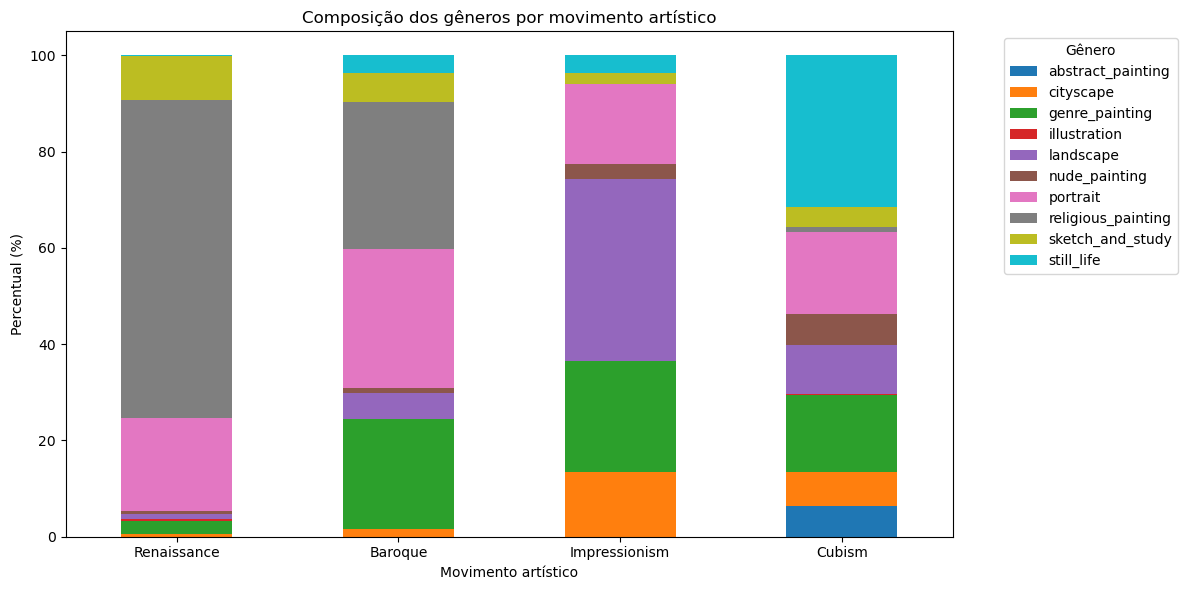

In [38]:
tabela_generos_sem_unknown.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
)

plt.title("Composição dos gêneros por movimento artístico")
plt.xlabel("Movimento artístico")
plt.ylabel("Percentual (%)")
plt.xticks(rotation=0)

plt.legend(
    title="Gênero",
    bbox_to_anchor=(1.05, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

In [39]:
top3_generos_conhecidos = (
    tabela_generos_sem_unknown
    .stack()
    .rename("Percentual")
    .reset_index()
    .sort_values(
        ["Macro_Estilo", "Percentual"],
        ascending=[True, False],
    )
    .groupby("Macro_Estilo")
    .head(3)
)

display(top3_generos_conhecidos)

,Macro_Estilo,Genero,Percentual
17,Baroque,religious_painting,30.62
16,Baroque,portrait,28.97
12,Baroque,genre_painting,22.73
39,Cubism,still_life,31.53
36,Cubism,portrait,17.07
32,Cubism,genre_painting,15.96
24,Impressionism,landscape,37.85
22,Impressionism,genre_painting,23.14
26,Impressionism,portrait,16.47
7,Renaissance,religious_painting,65.89


## 10. Quantificação das diferenças temáticas

Além da inspeção visual, as diferenças entre as classes são quantificadas em pontos percentuais.

São calculados:

- o maior contraste entre classes para cada gênero;
- as maiores diferenças gênero a gênero entre cada par de macroclasses;
- a distância de variação total entre as distribuições completas, usada como medida comparativa da diferença temática global entre pares de classes.

In [40]:
comparacao_generos = tabela_generos_sem_unknown.T.copy()

comparacao_generos["Maior_Percentual"] = (
    comparacao_generos[ordem_classes].max(axis=1)
)
comparacao_generos["Classe_Maior"] = (
    comparacao_generos[ordem_classes].idxmax(axis=1)
)
comparacao_generos["Menor_Percentual"] = (
    comparacao_generos[ordem_classes].min(axis=1)
)
comparacao_generos["Classe_Menor"] = (
    comparacao_generos[ordem_classes].idxmin(axis=1)
)
comparacao_generos["Diferenca_pp"] = (
    comparacao_generos["Maior_Percentual"]
    - comparacao_generos["Menor_Percentual"]
).round(2)

comparacao_generos = comparacao_generos.sort_values(
    "Diferenca_pp",
    ascending=False,
)

display(comparacao_generos)

Macro_Estilo,Renaissance,Baroque,Impressionism,Cubism,Maior_Percentual,Classe_Maior,Menor_Percentual,Classe_Menor,Diferenca_pp
Genero,,,,,,,,,
religious_painting,65.89,30.62,0.16,0.97,65.89,Renaissance,0.16,Impressionism,65.73
landscape,1.03,5.29,37.85,10.25,37.85,Impressionism,1.03,Renaissance,36.82
still_life,0.16,3.61,3.74,31.53,31.53,Cubism,0.16,Renaissance,31.37
genre_painting,2.71,22.73,23.14,15.96,23.14,Impressionism,2.71,Renaissance,20.43
cityscape,0.53,1.60,13.40,7.16,13.40,Impressionism,0.53,Renaissance,12.87
portrait,19.33,28.97,16.47,17.07,28.97,Baroque,16.47,Impressionism,12.50
sketch_and_study,9.19,5.97,2.12,4.16,9.19,Renaissance,2.12,Impressionism,7.07
abstract_painting,0.00,0.03,0.00,6.29,6.29,Cubism,0.00,Renaissance,6.29
nude_painting,0.73,1.01,3.12,6.38,6.38,Cubism,0.73,Renaissance,5.65


In [41]:
diferencas_pares = []

for classe_a, classe_b in combinations(ordem_classes, 2):
    for genero in tabela_generos_sem_unknown.columns:
        percentual_a = tabela_generos_sem_unknown.loc[classe_a, genero]
        percentual_b = tabela_generos_sem_unknown.loc[classe_b, genero]

        diferencas_pares.append({
            "Classe_A": classe_a,
            "Classe_B": classe_b,
            "Genero": genero,
            "Percentual_A": percentual_a,
            "Percentual_B": percentual_b,
            "Diferenca_pp": round(abs(percentual_a - percentual_b), 2),
        })

df_diferencas_pares = (
    pd.DataFrame(diferencas_pares)
    .sort_values("Diferenca_pp", ascending=False)
    .reset_index(drop=True)
)

display(df_diferencas_pares.head(15))

,Classe_A,Classe_B,Genero,Percentual_A,Percentual_B,Diferenca_pp
0,Renaissance,Impressionism,religious_painting,65.89,0.16,65.73
1,Renaissance,Cubism,religious_painting,65.89,0.97,64.92
2,Renaissance,Impressionism,landscape,1.03,37.85,36.82
3,Renaissance,Baroque,religious_painting,65.89,30.62,35.27
4,Baroque,Impressionism,landscape,5.29,37.85,32.56
5,Renaissance,Cubism,still_life,0.16,31.53,31.37
6,Baroque,Impressionism,religious_painting,30.62,0.16,30.46
7,Baroque,Cubism,religious_painting,30.62,0.97,29.65
8,Baroque,Cubism,still_life,3.61,31.53,27.92
9,Impressionism,Cubism,still_life,3.74,31.53,27.79


In [42]:
distancias = []

for classe_a, classe_b in combinations(ordem_classes, 2):
    distribuicao_a = tabela_generos_sem_unknown.loc[classe_a] / 100
    distribuicao_b = tabela_generos_sem_unknown.loc[classe_b] / 100

    distancia = 0.5 * (distribuicao_a - distribuicao_b).abs().sum()

    distancias.append({
        "Classe_A": classe_a,
        "Classe_B": classe_b,
        "Distancia_Variacao_Total": round(distancia, 3),
    })

df_distancia_generos = (
    pd.DataFrame(distancias)
    .sort_values("Distancia_Variacao_Total", ascending=False)
    .reset_index(drop=True)
)

display(df_distancia_generos)

,Classe_A,Classe_B,Distancia_Variacao_Total
0,Renaissance,Impressionism,0.761
1,Renaissance,Cubism,0.724
2,Baroque,Cubism,0.501
3,Baroque,Impressionism,0.470
4,Impressionism,Cubism,0.410
5,Renaissance,Baroque,0.387


## 11. Conclusões da análise exploratória

A EDA identificou pontos centrais para a construção do experimento:

- O WikiArt possui volume suficiente para as quatro macroclasses selecionadas.
- `Unknown Artist` ocorre com frequência relevante e não será tratado como um único autor.
- `Unknown Genre` também representa uma limitação dos metadados e deve ser documentado separadamente.
- A distribuição temática não é homogênea entre as macroclasses.
- O Renascimento apresenta forte predominância de `religious_painting`.
- O Impressionismo apresenta concentração relevante de `landscape`.
- O Cubismo apresenta concentração relevante de `still_life`.
- O Barroco possui distribuição temática comparativamente mais heterogênea.
- Essas diferenças podem favorecer *shortcut learning* e, portanto, não devem ser ignoradas na interpretação do desempenho da rede.

### Decisão metodológica após a EDA

O dataset principal será balanceado **por macroclasse**, utilizando a disponibilidade final do Cubismo como referência e tendo como meta provisória até **2.500 pinturas válidas por classe**.

A distribuição temática natural não será artificialmente igualada no conjunto principal. Em etapa posterior, será realizado um **experimento de controle temático**, inicialmente planejado com obras do gênero `portrait`, presente nas quatro macroclasses.

### Próxima etapa

A próxima etapa será realizada em `02_curadoria_dataset.ipynb` e incluirá:

1. auditoria de integridade das imagens;
2. análise das dimensões;
3. definição do número final de obras por macroclasse;
4. amostragem reproduzível;
5. geração do manifesto do dataset;
6. divisão por pintura em treino, validação e teste.